<a href="https://colab.research.google.com/github/jad-r-s/Jad_INFO4670_Fall2026/blob/main/JadSaboune_Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [1]:
#Please write the code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 42

# Load the dataset
df = pd.read_csv("car_purchase_data.csv")

# Quick look at the data
print("Shape:", df.shape)
display(df.head())
display(df.describe())

# Check for missing values and class balance
print("Missing values:\n", df.isnull().sum())
print("\nPurchased counts:\n", df["Purchased"].value_counts())


Shape: (400, 5)


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


,User ID,Age,Salary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


Missing values:
 User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64

Purchased counts:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 2: Split features and target

In [2]:
#Please write the code here
X = df[["Age", "Salary"]]
y = df["Purchased"]

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (400, 2)
y shape: (400,)


,Age,Salary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


### Step 3: Train/Test Split

In [3]:
#Please write the code here
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (300, 2)
Test set: (100, 2)


### Step 4: Feature Scaling

In [4]:
#Please write the code here
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data (first 5 rows):")
print(X_train_scaled[:5])

Scaled training data (first 5 rows):
[[ 0.45809581  0.54309037]
 [ 0.17532062  0.71372445]
 [-0.57874655  1.33938275]
 [-0.57874655 -1.04949441]
 [ 0.83512939  0.23026122]]


### Step 5: Train Logistic Regression Model

In [6]:
#Please write the code here
model = LogisticRegression(random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)

print("Coefficients (Age, Salary):", model.coef_[0])
print("Intercept:", model.intercept_[0])

Coefficients (Age, Salary): [2.14393972 1.21072966]
Intercept: -1.120157162941337


### Step 6: Predict and Evaluate

Accuracy: 0.84


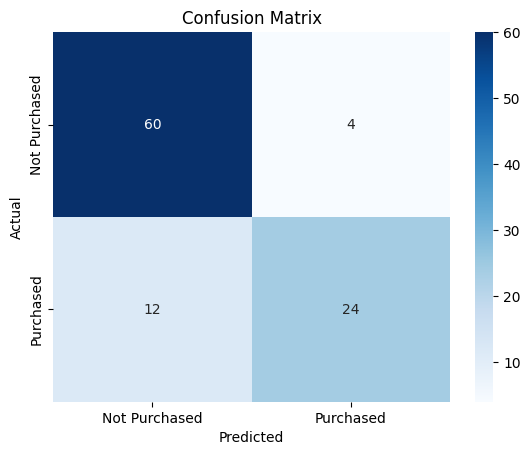

               precision    recall  f1-score   support

Not Purchased       0.83      0.94      0.88        64
    Purchased       0.86      0.67      0.75        36

     accuracy                           0.84       100
    macro avg       0.85      0.80      0.82       100
 weighted avg       0.84      0.84      0.83       100



In [7]:
#Please write the code here
y_pred = model.predict(X_test_scaled)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Purchased", "Purchased"],
            yticklabels=["Not Purchased", "Purchased"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Precision, recall, and F1 for each class
print(classification_report(y_test, y_pred, target_names=["Not Purchased", "Purchased"]))

### Step 7: Visualization of Decision Regions

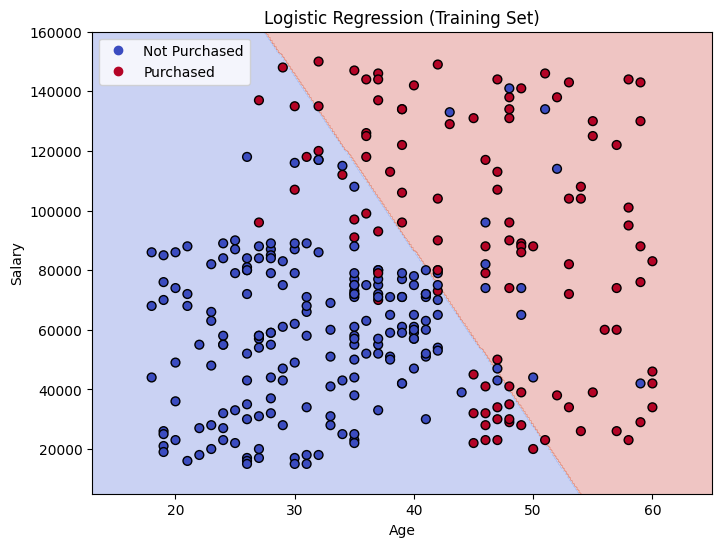

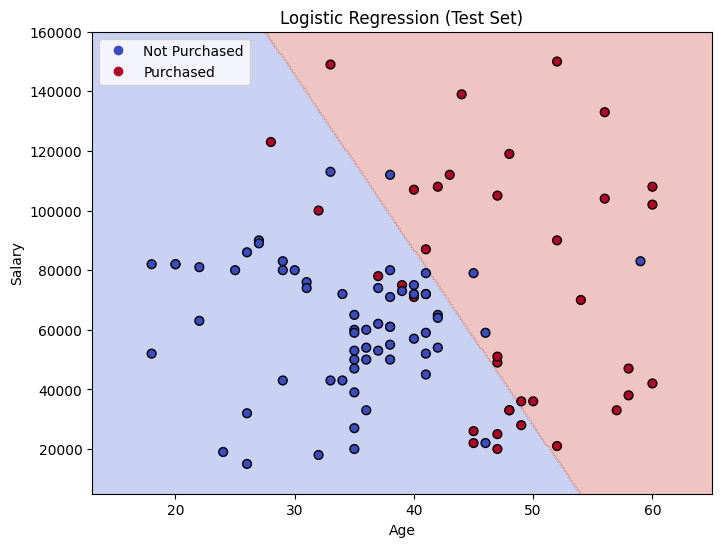

In [8]:
#Please write the code here
def plot_decision_regions(X_set, y_set, title):
    # Create a grid covering the range of Age and Salary
    age_range = np.linspace(X_set["Age"].min() - 5, X_set["Age"].max() + 5, 300)
    salary_range = np.linspace(X_set["Salary"].min() - 10000, X_set["Salary"].max() + 10000, 300)
    age_grid, salary_grid = np.meshgrid(age_range, salary_range)

    # Scale the grid points and predict a class for each one
    grid = pd.DataFrame({"Age": age_grid.ravel(), "Salary": salary_grid.ravel()})
    predictions = model.predict(scaler.transform(grid)).reshape(age_grid.shape)

    # Shade the regions and overlay the actual data points
    plt.figure(figsize=(8, 6))
    plt.contourf(age_grid, salary_grid, predictions, alpha=0.3, cmap="coolwarm")
    scatter = plt.scatter(X_set["Age"], X_set["Salary"], c=y_set,
                          cmap="coolwarm", edgecolor="k", s=40)
    plt.legend(handles=scatter.legend_elements()[0],
               labels=["Not Purchased", "Purchased"])
    plt.xlabel("Age")
    plt.ylabel("Salary")
    plt.title(title)
    plt.show()


plot_decision_regions(X_train, y_train, "Logistic Regression (Training Set)")
plot_decision_regions(X_test, y_test, "Logistic Regression (Test Set)")

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. The sigmoid function turns the model’s output into a probability between 0 and 1. Applying a threshold (0.5 by default) converts that probability into a class: 1 if P ≥ 0.5, otherwise 0. The threshold can also be adjusted to favor precision or recall.
2. Both coefficients are positive (Age = 2.14, Salary = 1.21), so older and higher-earning customers are more likely to buy. Since the features are scaled, Age has about 1.8 times the effect of Salary, making it the stronger predictor.
3. The model reached 84% accuracy, but 12 of its 16 errors were missed buyers, giving a recall of only 0.67 for “Purchased.” Likely causes are class imbalance (64/36), a linear boundary that can’t capture curved patterns, only two features, and a small test set.
4. Additional features such as gender, marital status, number of dependents, current car ownership, or credit score could help. On the modeling side, using class_weight="balanced" or a lower threshold would improve recall, while polynomial features, cross-validation, and tuning C could improve overall performance.